# XAI-STIM: complete sample classification pipeline

This notebook runs the repository's existing pipeline on `sample_data.npz` and `sample_meta.csv`: data import, resampling, one-second windowing, preprocessing, classification, and 1D Grad-CAM explanation. Every processing, inference, metric, and explanation operation is imported from `modules/01_data_preparation` and `modules/02_XAI-STIM`.

Figures are saved under `results/main_figures/`.

In [48]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import signal

ROOT = Path.cwd().resolve()
PREPARATION = ROOT / 'modules' / '01_data_preparation'
XAI = ROOT / 'modules' / '02_XAI-STIM'
sys.path.insert(0, str(PREPARATION))
sys.path.insert(0, str(XAI))

from processing import (
    SAMPLING_FREQUENCIES, TARGET_FS, WINDOW, filter_signals,
    highpass_filter, load_matrix, process_signals, resample_signals,
    split_signals, zscore_normalize,
)
from inference import MODELS, inference
from compute_performances import compute_metrics
from gradcam1D import gradcam1D, plot_gradcam

FIGURES = ROOT / 'results' / 'main_figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 300, 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Import the sample data

Loaded 11 traces with shape (11, 100000) at 20,000 Hz.


,patient,side,dataset,depth,electrode,length,class
0,P018,LEFT,NeuroSet,-8000,Electrode1,100000,0
1,P018,LEFT,NeuroSet,-6000,Electrode1,100000,0
2,P018,LEFT,NeuroSet,-4000,Electrode1,100000,0
3,P018,LEFT,NeuroSet,-3000,Electrode1,100000,0
4,P018,LEFT,NeuroSet,-2000,Electrode1,100000,1
5,P018,LEFT,NeuroSet,-1000,Electrode1,100000,1
6,P018,LEFT,NeuroSet,0,Electrode1,100000,1
7,P018,LEFT,NeuroSet,1000,Electrode1,100000,1
8,P018,LEFT,NeuroSet,2000,Electrode1,100000,1
9,P018,LEFT,NeuroSet,3000,Electrode1,100000,1


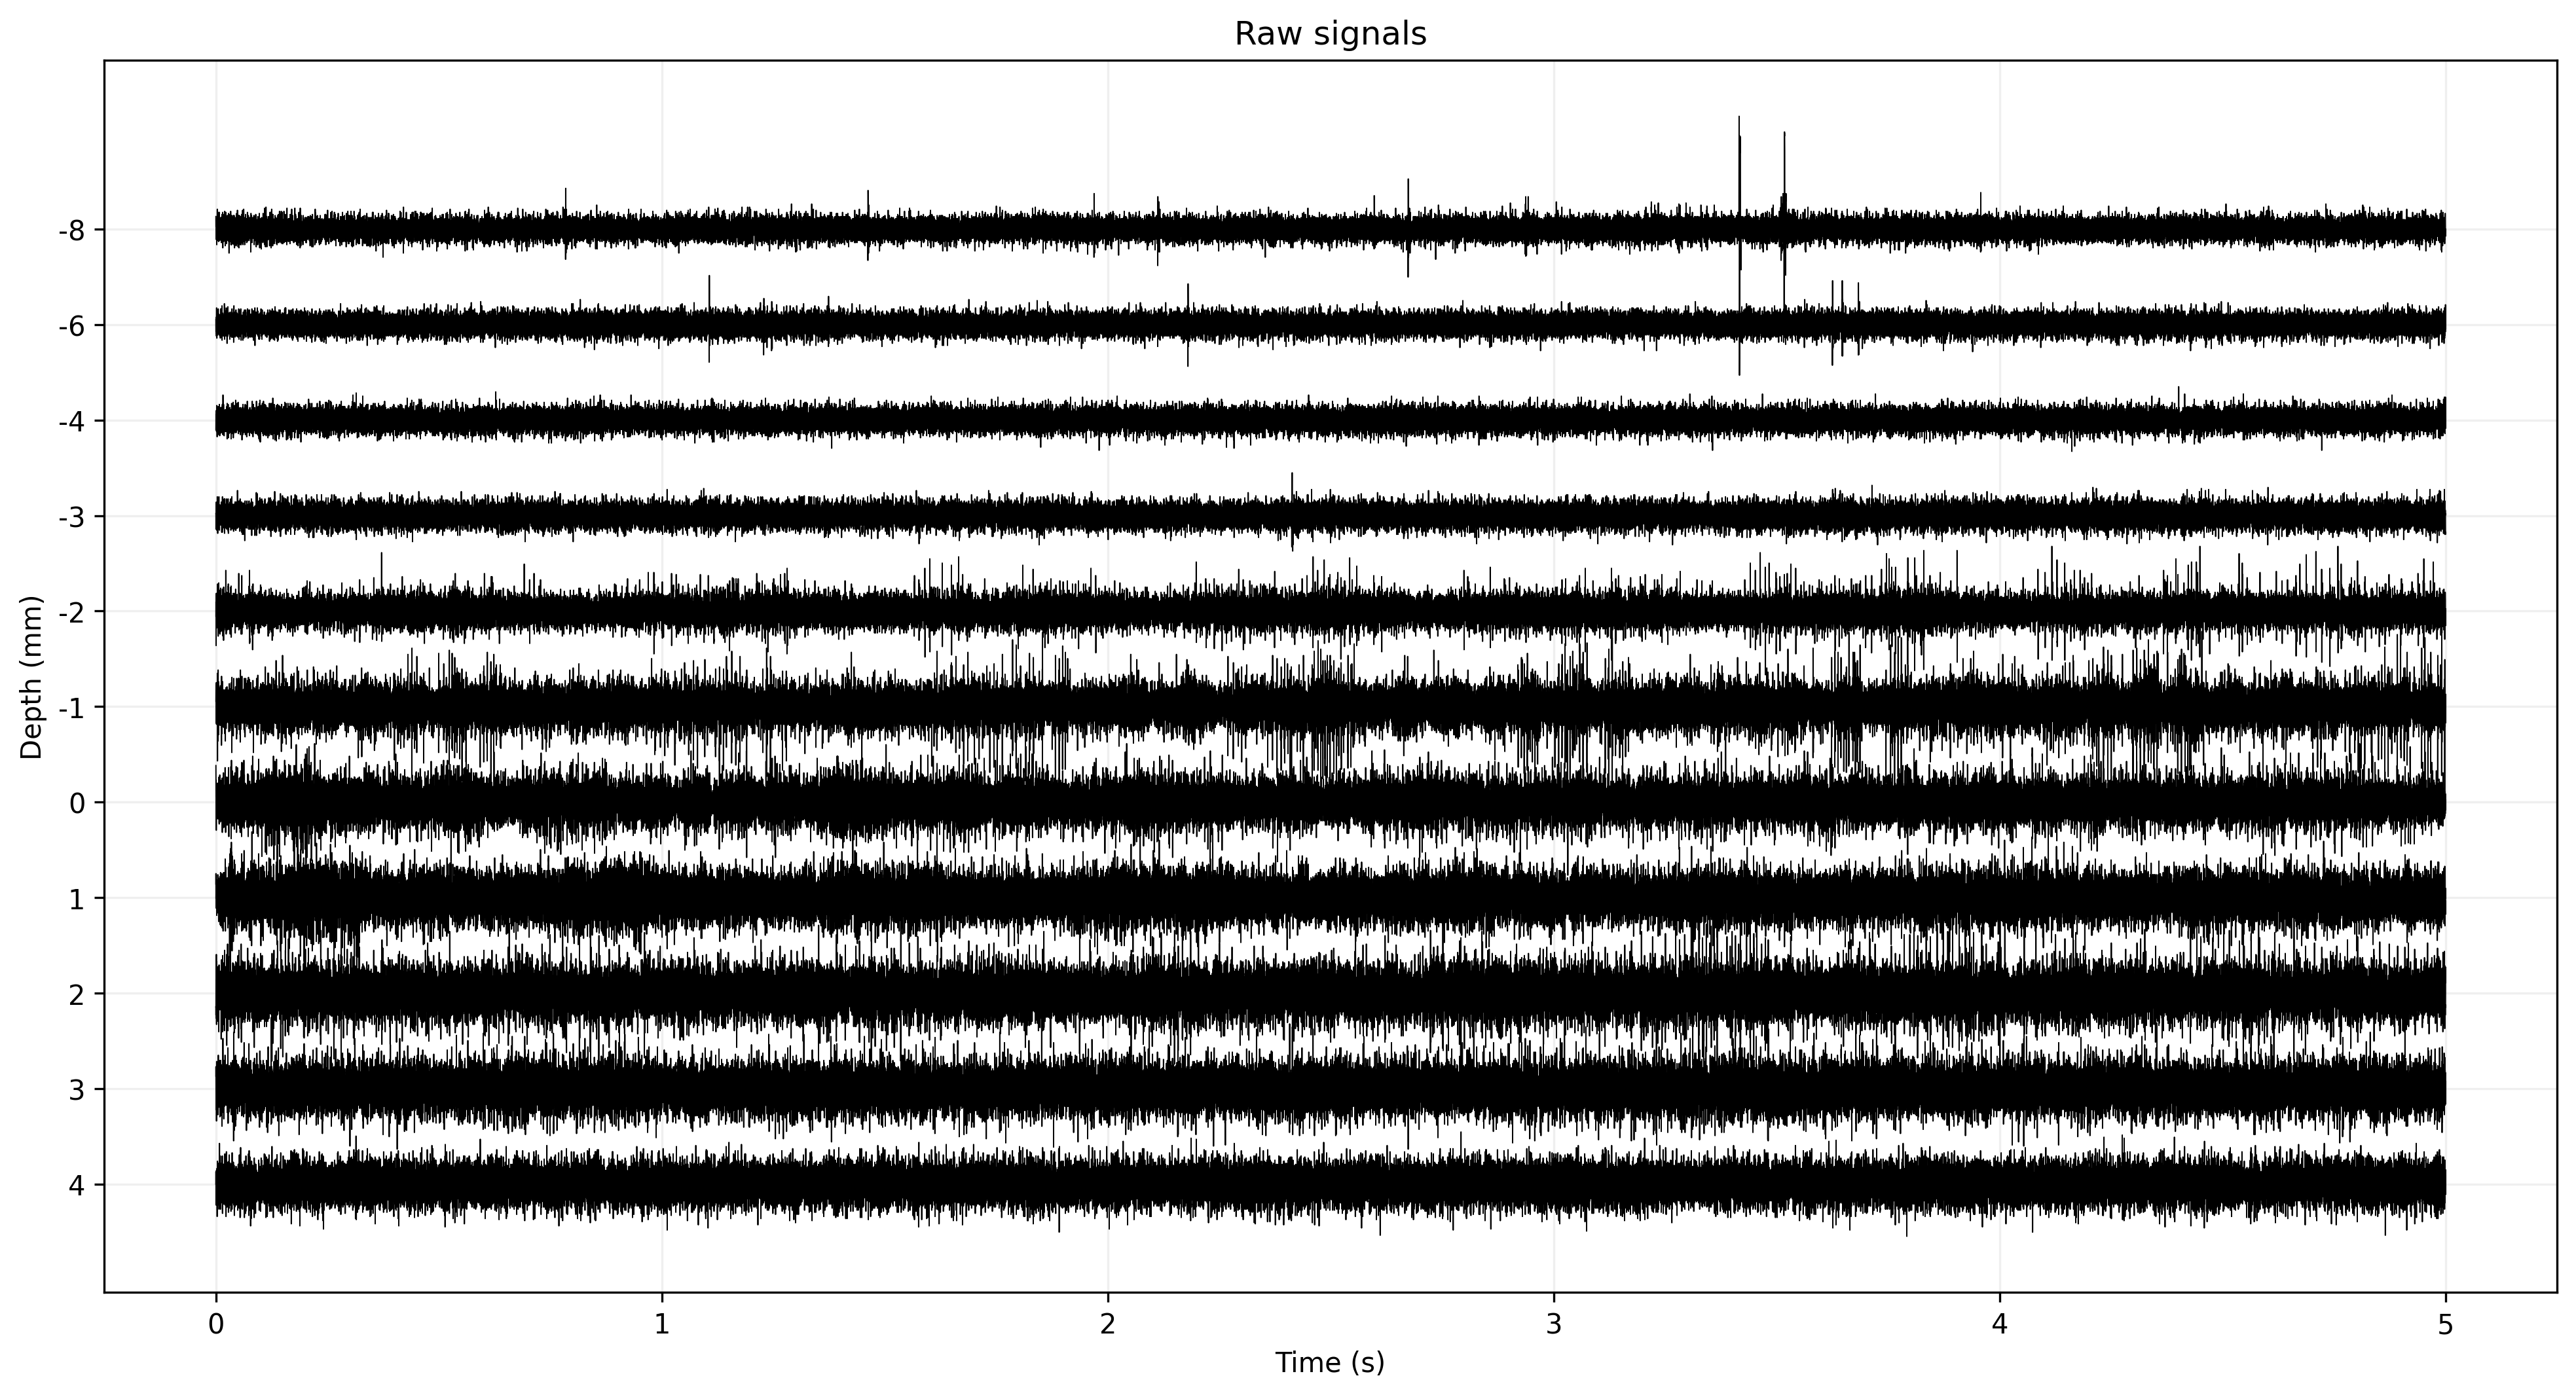

In [49]:
raw = load_matrix(ROOT / 'sample_data.npz')
metadata = pd.read_csv(ROOT / 'sample_meta.csv', dtype={'patient': str})

dataset = metadata['dataset'].dropna().unique()
original_fs = SAMPLING_FREQUENCIES[dataset[0]]
print(f'Loaded {len(raw)} traces with shape {raw.shape} at {original_fs:,} Hz.')
display(metadata)

order = np.argsort(metadata['depth'].to_numpy())
display_samples = int(metadata['length'].min())
time_raw = np.arange(display_samples) / original_fs
raw_scale = np.percentile(np.abs(raw[:, :display_samples]), 99)
fig, ax = plt.subplots(figsize=(13, 7), layout='constrained')
for position, row_index in enumerate(order):
    trace = raw[row_index, :display_samples]
    ax.plot(time_raw, trace / raw_scale * 0.35 - position, color='black', linewidth=0.45)
ax.set(yticks=-np.arange(len(order)), yticklabels=(metadata.iloc[order]['depth'] / 1000).map('{:g}'.format),
       xlabel='Time (s)', ylabel='Depth (mm)', title='Raw signals')
fig.savefig(FIGURES / '01_raw_signals.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Resample to the model frequency

`resample_signals` applies an anti-alias low-pass filter and converts recordings to the model's 10 kHz sampling frequency.

Resampled shape: (11, 50000); target frequency: 10,000 Hz


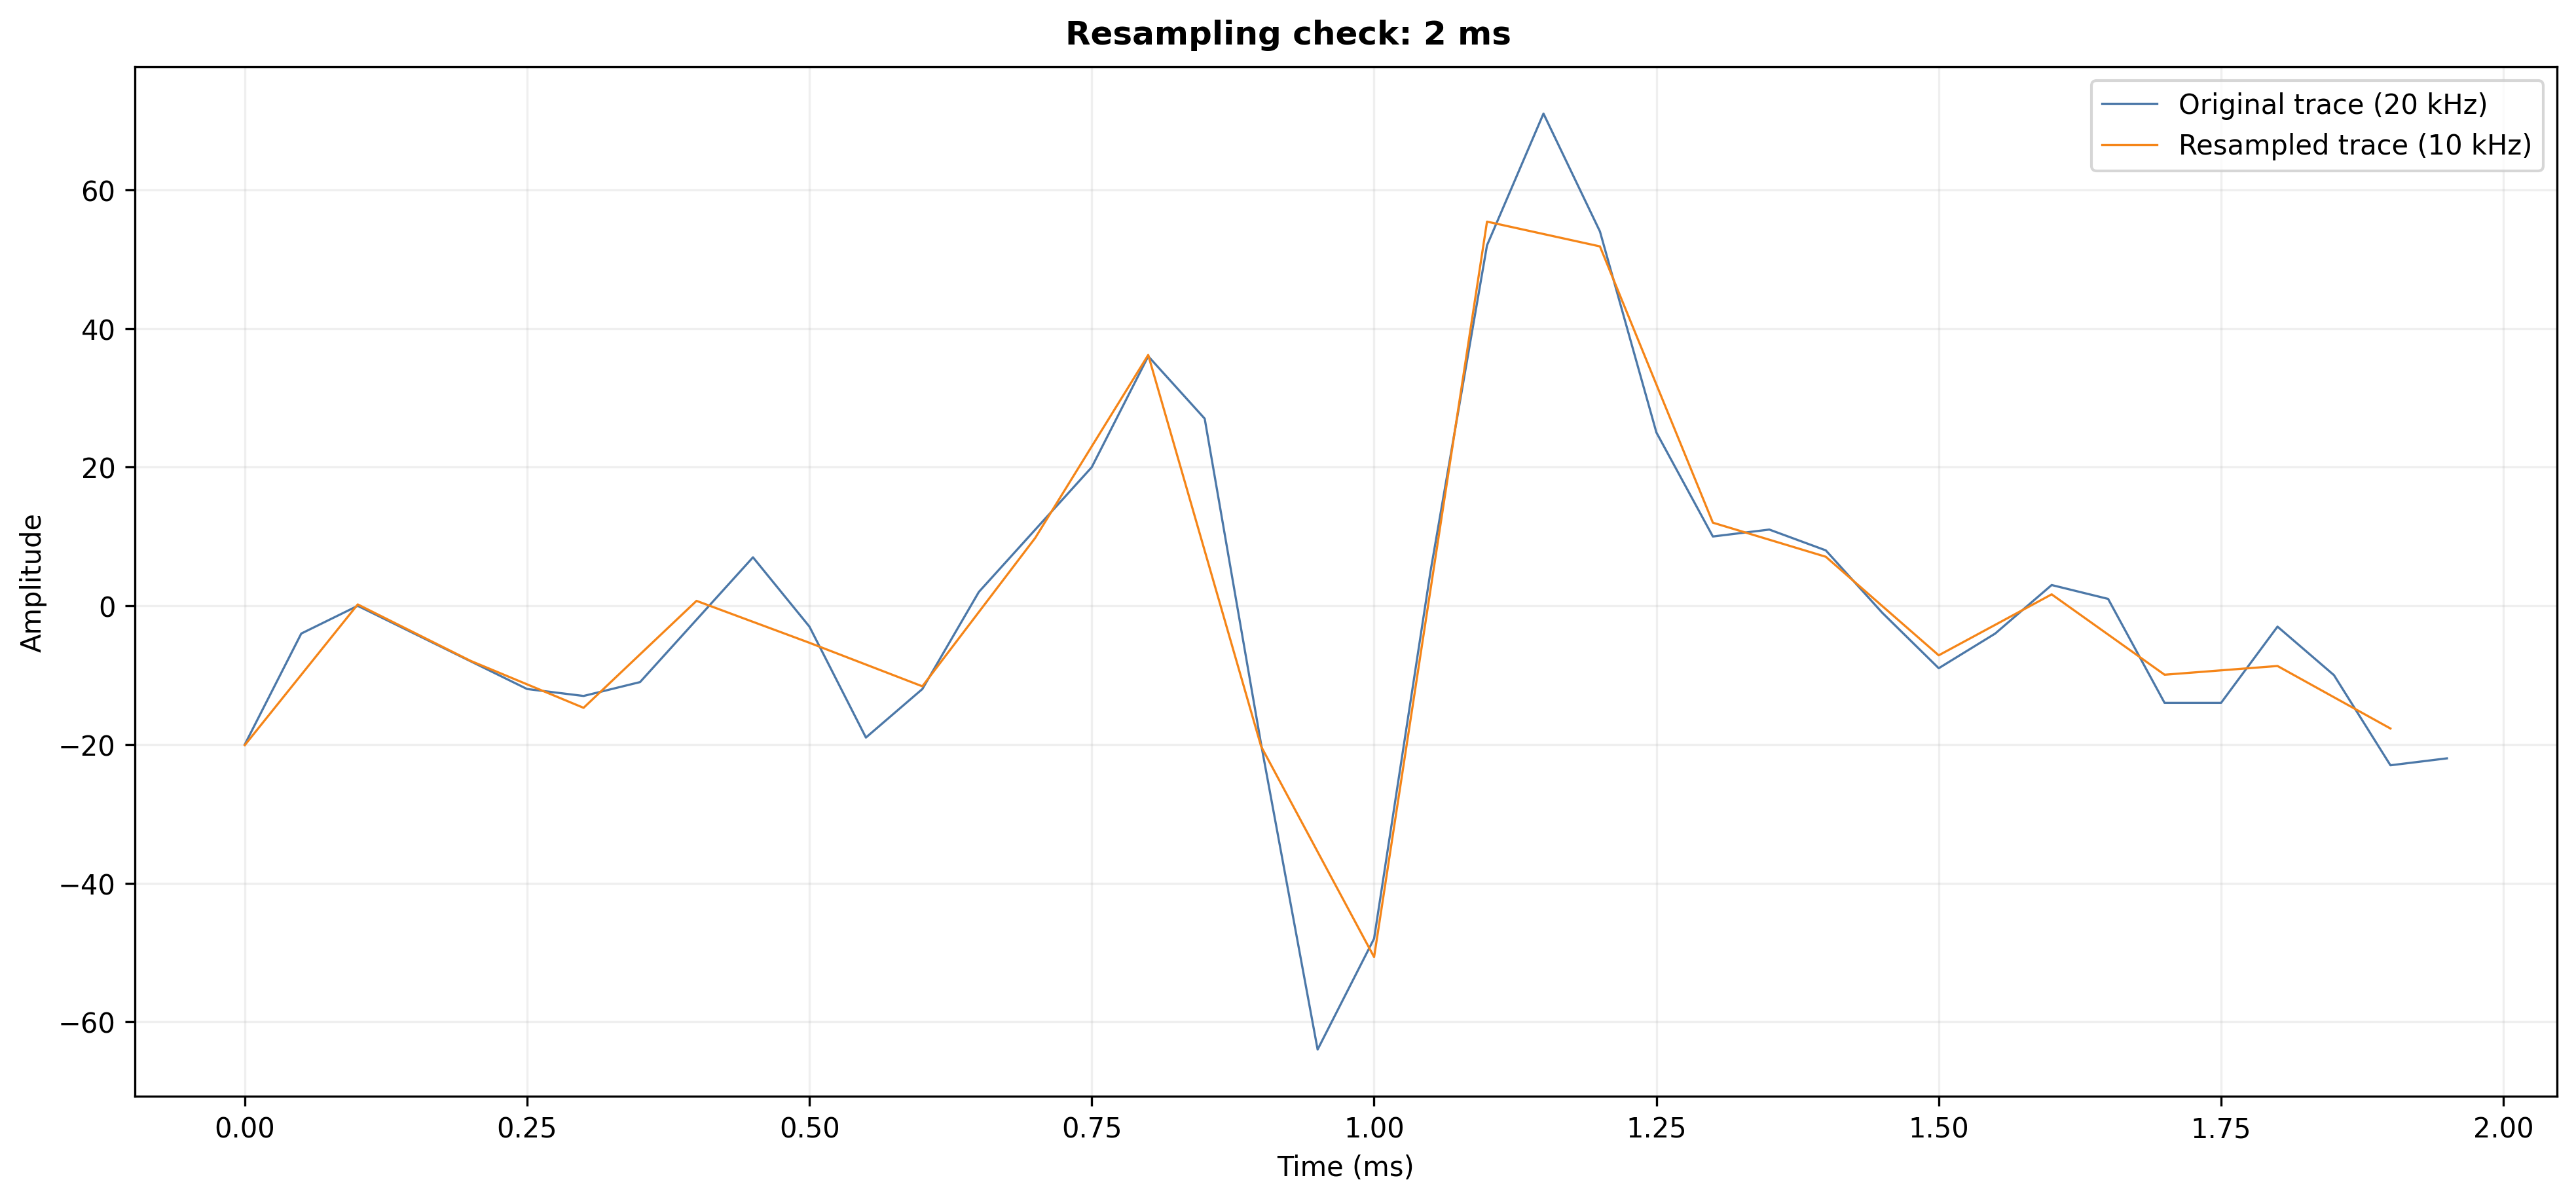

In [50]:
resampled, resampled_metadata = resample_signals(raw, metadata, original_fs)
print(f'Resampled shape: {resampled.shape}; target frequency: {TARGET_FS:,} Hz')

comparison_seconds = 0.002
raw_count = round(comparison_seconds * original_fs)
resampled_count = round(comparison_seconds * TARGET_FS)
fig, axes = plt.subplots(1, 1, figsize=(13, 6), sharex=True, layout='constrained')
start = 37050
axes.plot(np.arange(raw_count) / original_fs * 1000, raw[5, start:start+raw_count], color='#4c78a8', linewidth=0.8, label=f'Original trace ({original_fs / 1000:g} kHz)')
axes.set(ylabel='Amplitude')
axes.plot(np.arange(resampled_count) / TARGET_FS * 1000, resampled[5, int(start/original_fs*TARGET_FS):int(start/original_fs*TARGET_FS+resampled_count)], color='#f58518', linewidth=0.8, label=f'Resampled trace ({TARGET_FS / 1000:g} kHz)')
axes.set(xlabel='Time (ms)', ylabel='Amplitude')
axes.legend()
fig.suptitle('Resampling check: 2 ms', fontweight='bold')
fig.savefig(FIGURES / '02_resampling.png', dpi=180, bbox_inches='tight')
plt.show()

## 3. Split recordings into one-second windows

`split_signals` uses the sample patient's class-specific overlap values from `results/overlap.csv`, exactly as the dataset preparation pipeline does.

Created 100 windows of 10,000 samples.


,class,overlap,windows
0,0,0.7,70
1,1,0.0,30


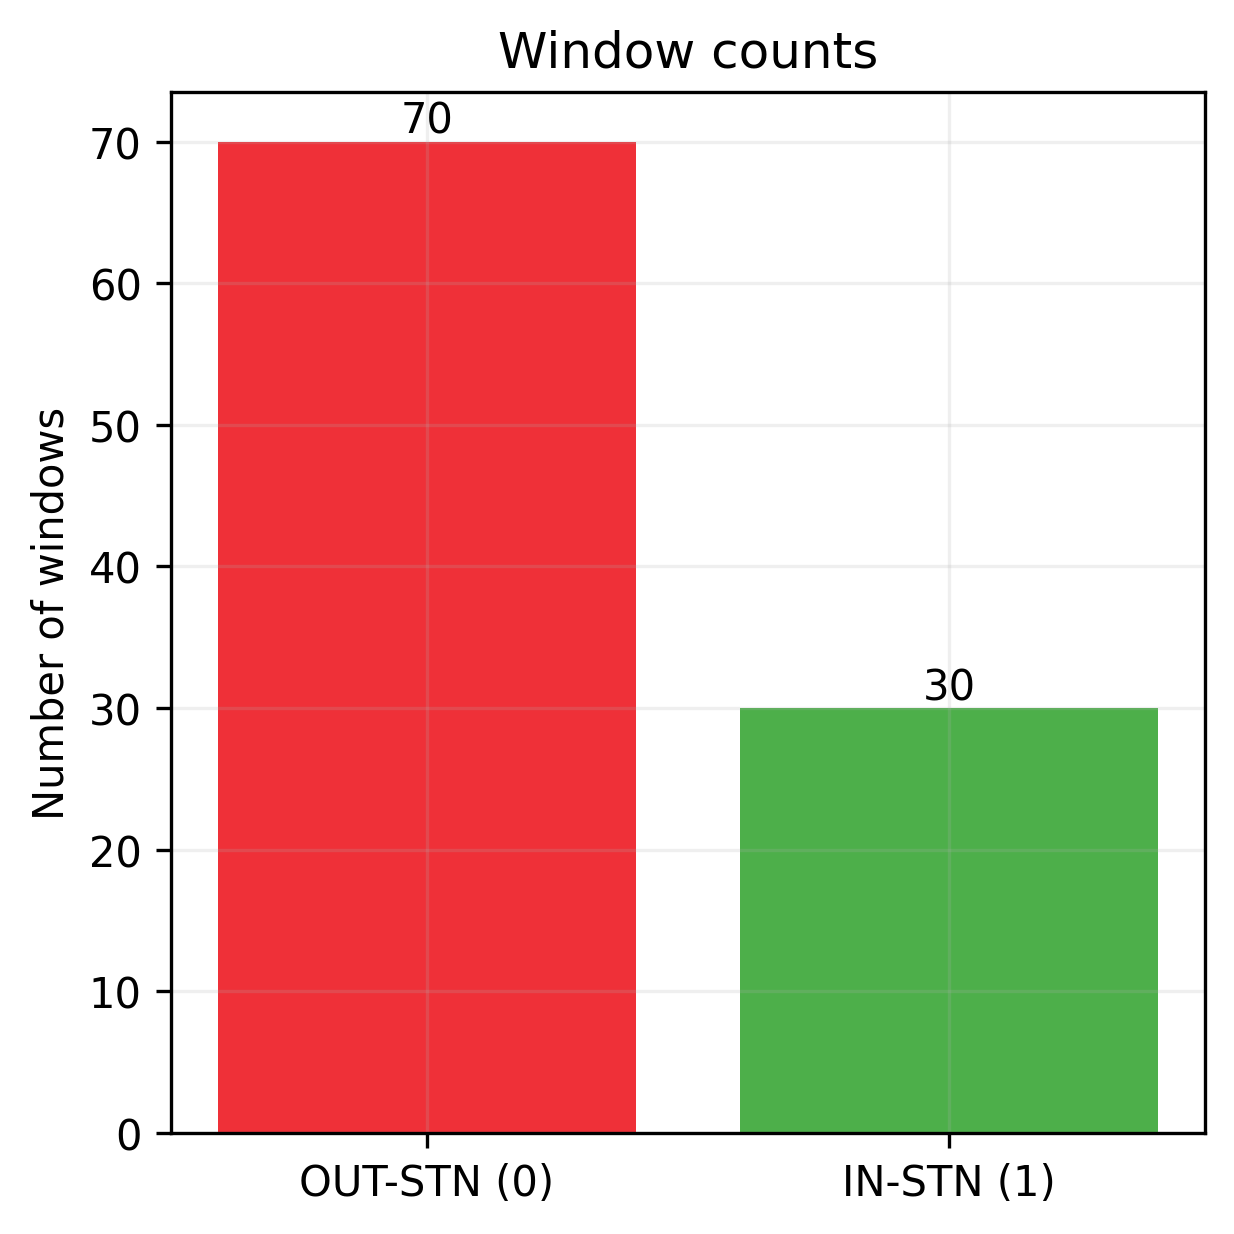

In [66]:
overlaps = pd.read_csv(ROOT / 'results' / 'overlap.csv', dtype={'patient': str})
windows, window_metadata = split_signals(resampled, resampled_metadata, overlaps)
print(f'Created {len(windows)} windows of {WINDOW:,} samples.')
display(window_metadata.groupby(['class', 'overlap']).size().rename('windows').reset_index())

fig, axes = plt.subplots(1, 1, figsize=(4, 4), layout='constrained')
counts = window_metadata.groupby('class').size().reindex([0, 1], fill_value=0)
axes.bar(['OUT-STN (0)', 'IN-STN (1)'], counts.values, color=['#ef3038', '#4daf4a'])
axes.set(title='Window counts', ylabel='Number of windows')
axes.bar_label(axes.containers[0])
fig.savefig(FIGURES / '03_windowing.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Processing

Normalizes each one-second window before filtering. `highpass_filter` applies the 200 Hz high-pass filter; `filter_signals` applies that high-pass plus the 250–2950 Hz harmonic notch bank.

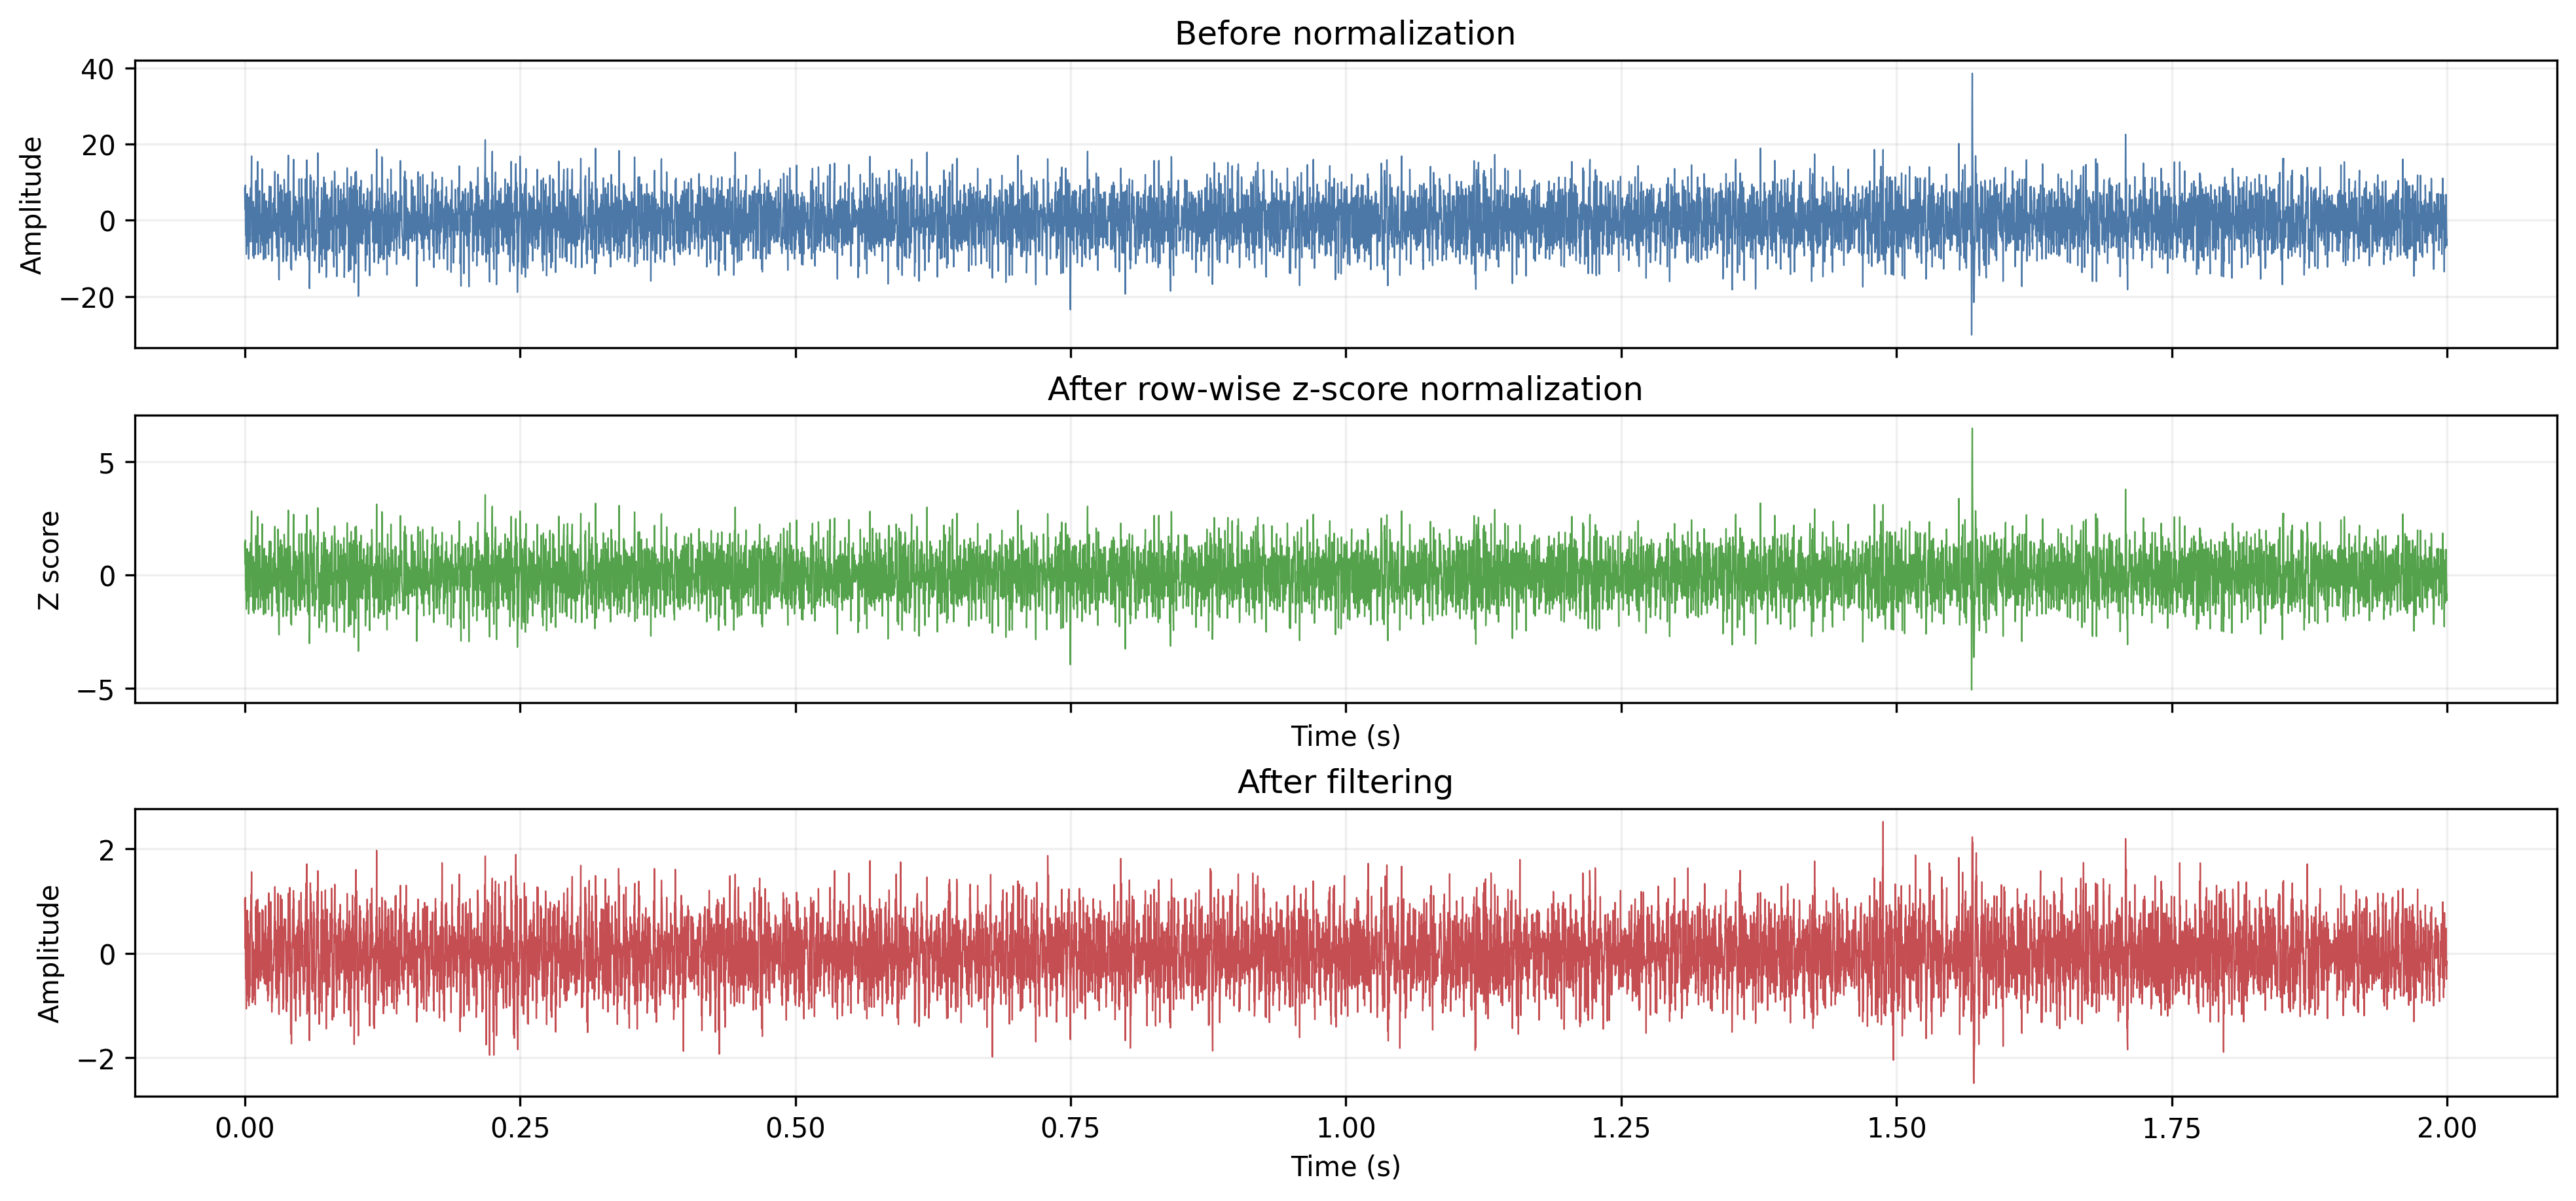

In [67]:
normalized = zscore_normalize(windows)
highpassed = highpass_filter(normalized)
processed = filter_signals(highpassed)

time_window = 2 * np.arange(WINDOW) / TARGET_FS
fig, axes = plt.subplots(3, 1, figsize=(13, 6), sharex=True, layout='constrained')
axes[0].plot(time_window, windows[0], color='#4c78a8', linewidth=0.55)
axes[0].set(title='Before normalization', ylabel='Amplitude')
axes[1].plot(time_window, normalized[0], color='#54a24b', linewidth=0.55)
axes[1].set(title='After row-wise z-score normalization', xlabel='Time (s)', ylabel='Z score')
axes[2].plot(time_window, processed[0], color='#c44e52', linewidth=0.55)
axes[2].set(title='After filtering', xlabel='Time (s)', ylabel='Amplitude')
fig.savefig(FIGURES / '04_processing.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Classify every window

The public `inference` API accepts raw 10 kHz windows and applies the same complete preprocessing internally before loading `all_in_one.pt`. The figure shows every window probability and the per-depth mean.

,n_samples,auc,f1_score,sensitivity,specificity
0,100,0.988,0.915,0.9,0.971


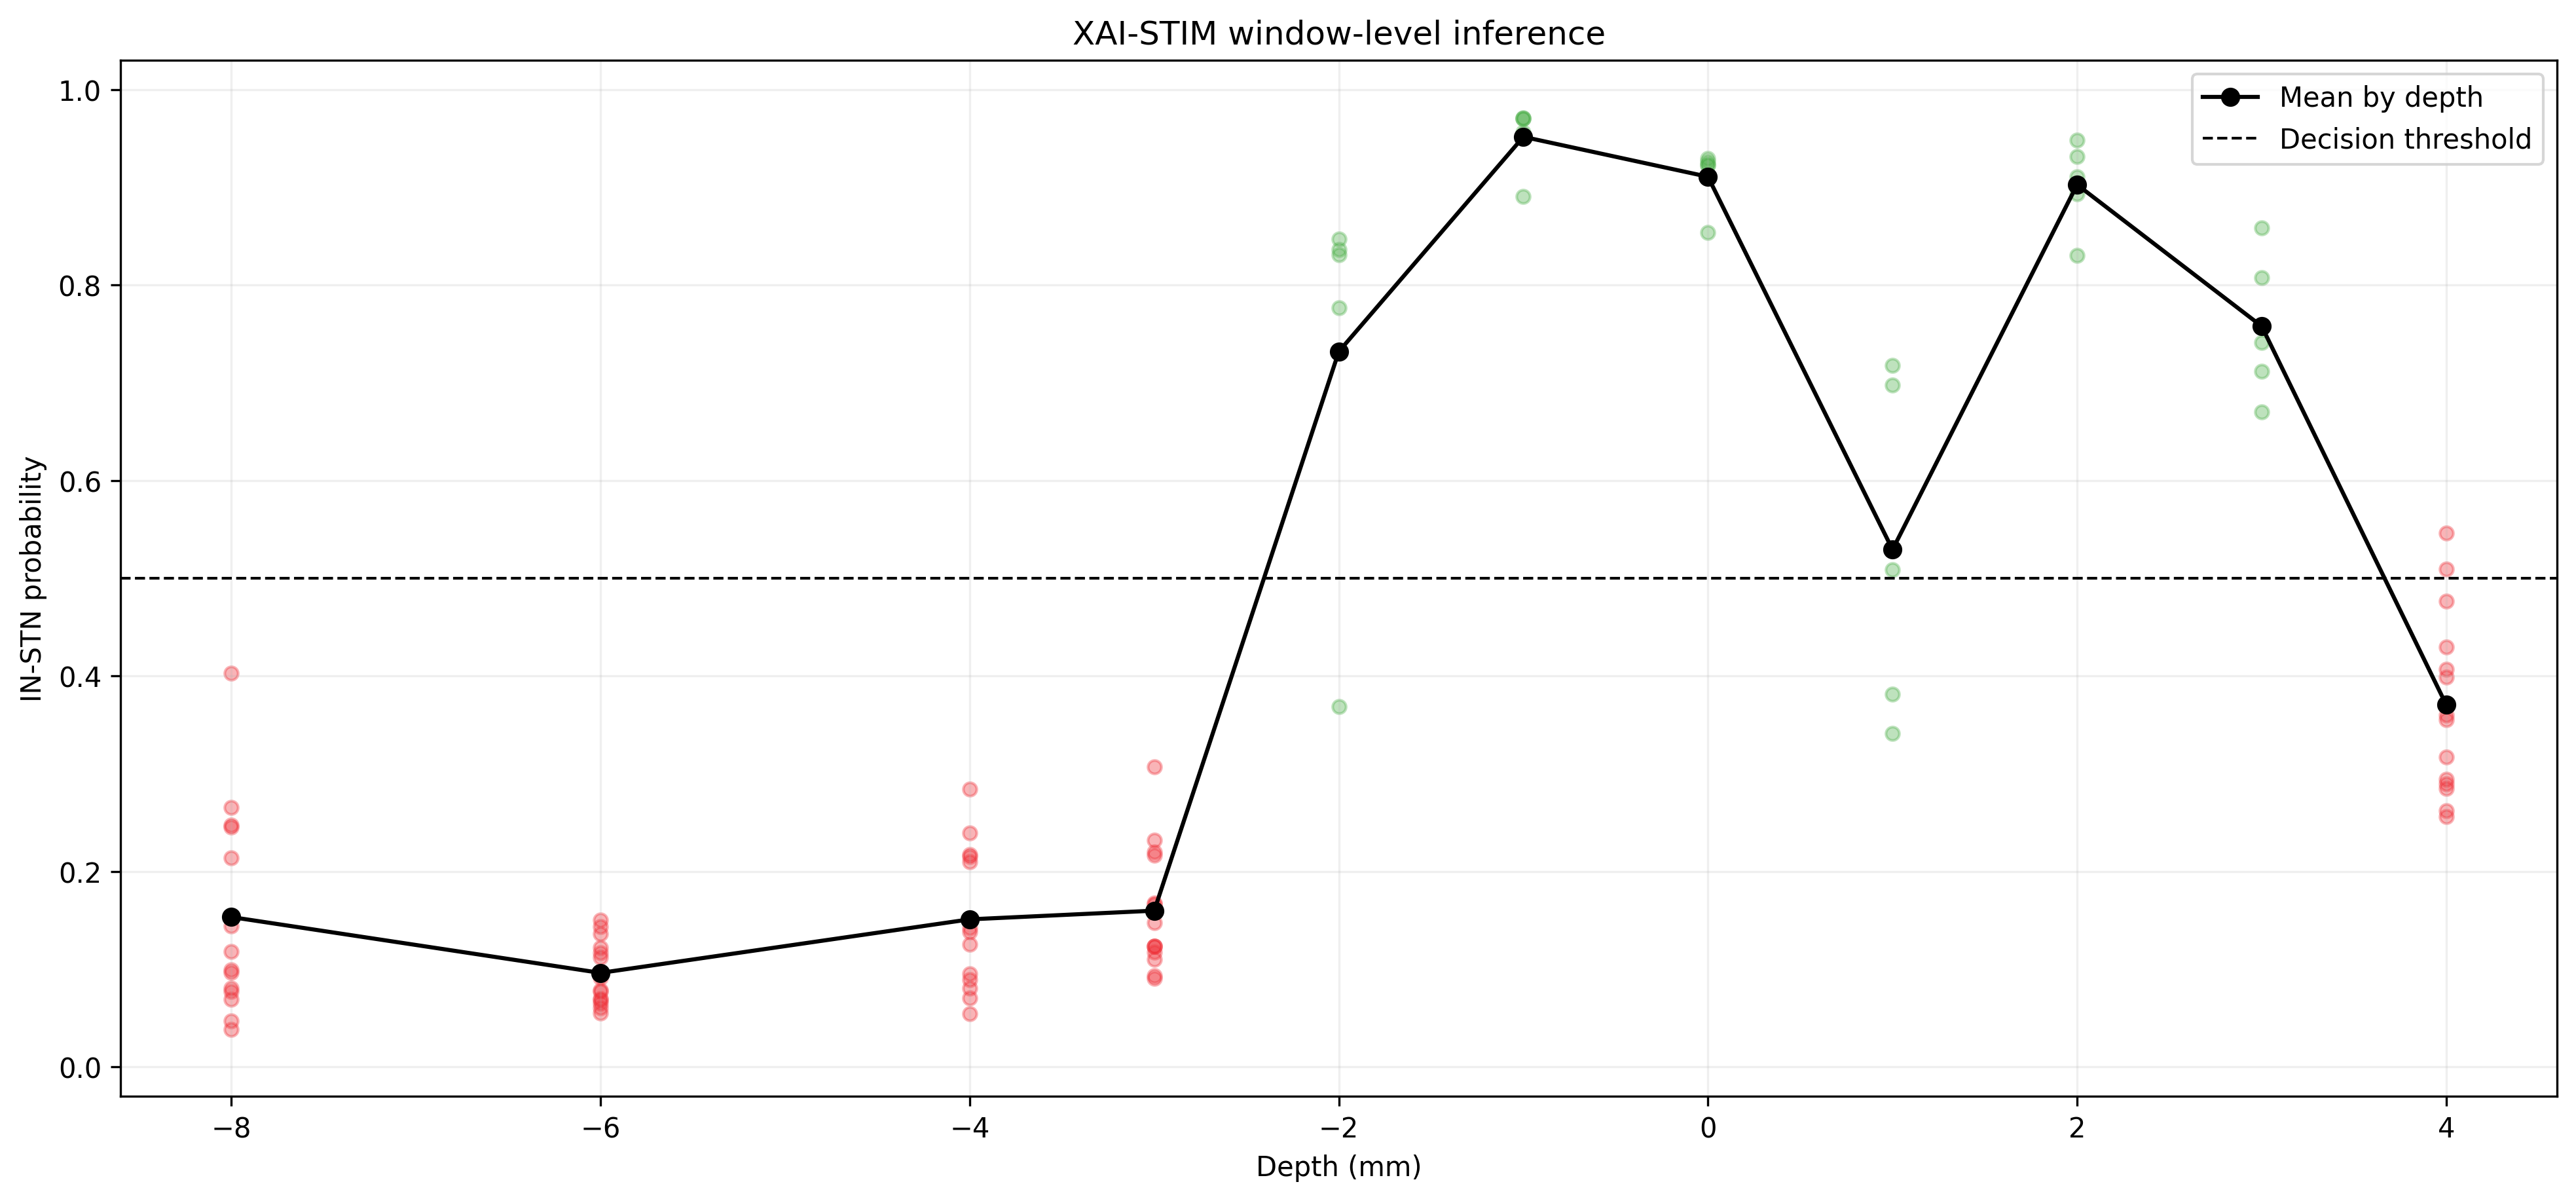

In [68]:
probabilities = inference(windows, model_path=MODELS / 'all_in_one.pt')
predictions = probabilities.argmax(axis=1)
prediction_table = window_metadata.copy()
prediction_table['softmax0'] = probabilities[:, 0]
prediction_table['softmax1'] = probabilities[:, 1]
prediction_table['prediction'] = predictions
display(pd.DataFrame([compute_metrics(prediction_table)]).round(3))

depth_order = np.sort(prediction_table['depth'].unique())
fig, ax = plt.subplots(figsize=(13, 6), layout='constrained')
for depth in depth_order:
    rows = prediction_table[prediction_table['depth'] == depth]
    color = '#4daf4a' if int(rows['class'].iloc[0]) == 1 else '#ef3038'
    ax.scatter(np.full(len(rows), depth / 1000), rows['softmax1'], color=color, alpha=0.36, s=24)
means = prediction_table.groupby('depth', sort=True)['softmax1'].mean()
ax.plot(means.index / 1000, means.values, color='black', marker='o', linewidth=1.5, label='Mean by depth')
ax.axhline(0.5, color='black', linestyle='--', linewidth=1, label='Decision threshold')
ax.set(ylim=(-0.03, 1.03), xlabel='Depth (mm)', ylabel='IN-STN probability',
       title='XAI-STIM window-level inference')
ax.legend()
fig.savefig(FIGURES / '05_inference.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Generate Grad-CAM maps

`gradcam1D` explains class 1 across each complete resampled trace. It creates and preprocesses its own one-second model windows, computes attention-layer Grad-CAM, concatenates the maps, and smooths them. `plot_gradcam` overlays probability-scaled relevance on the signals.

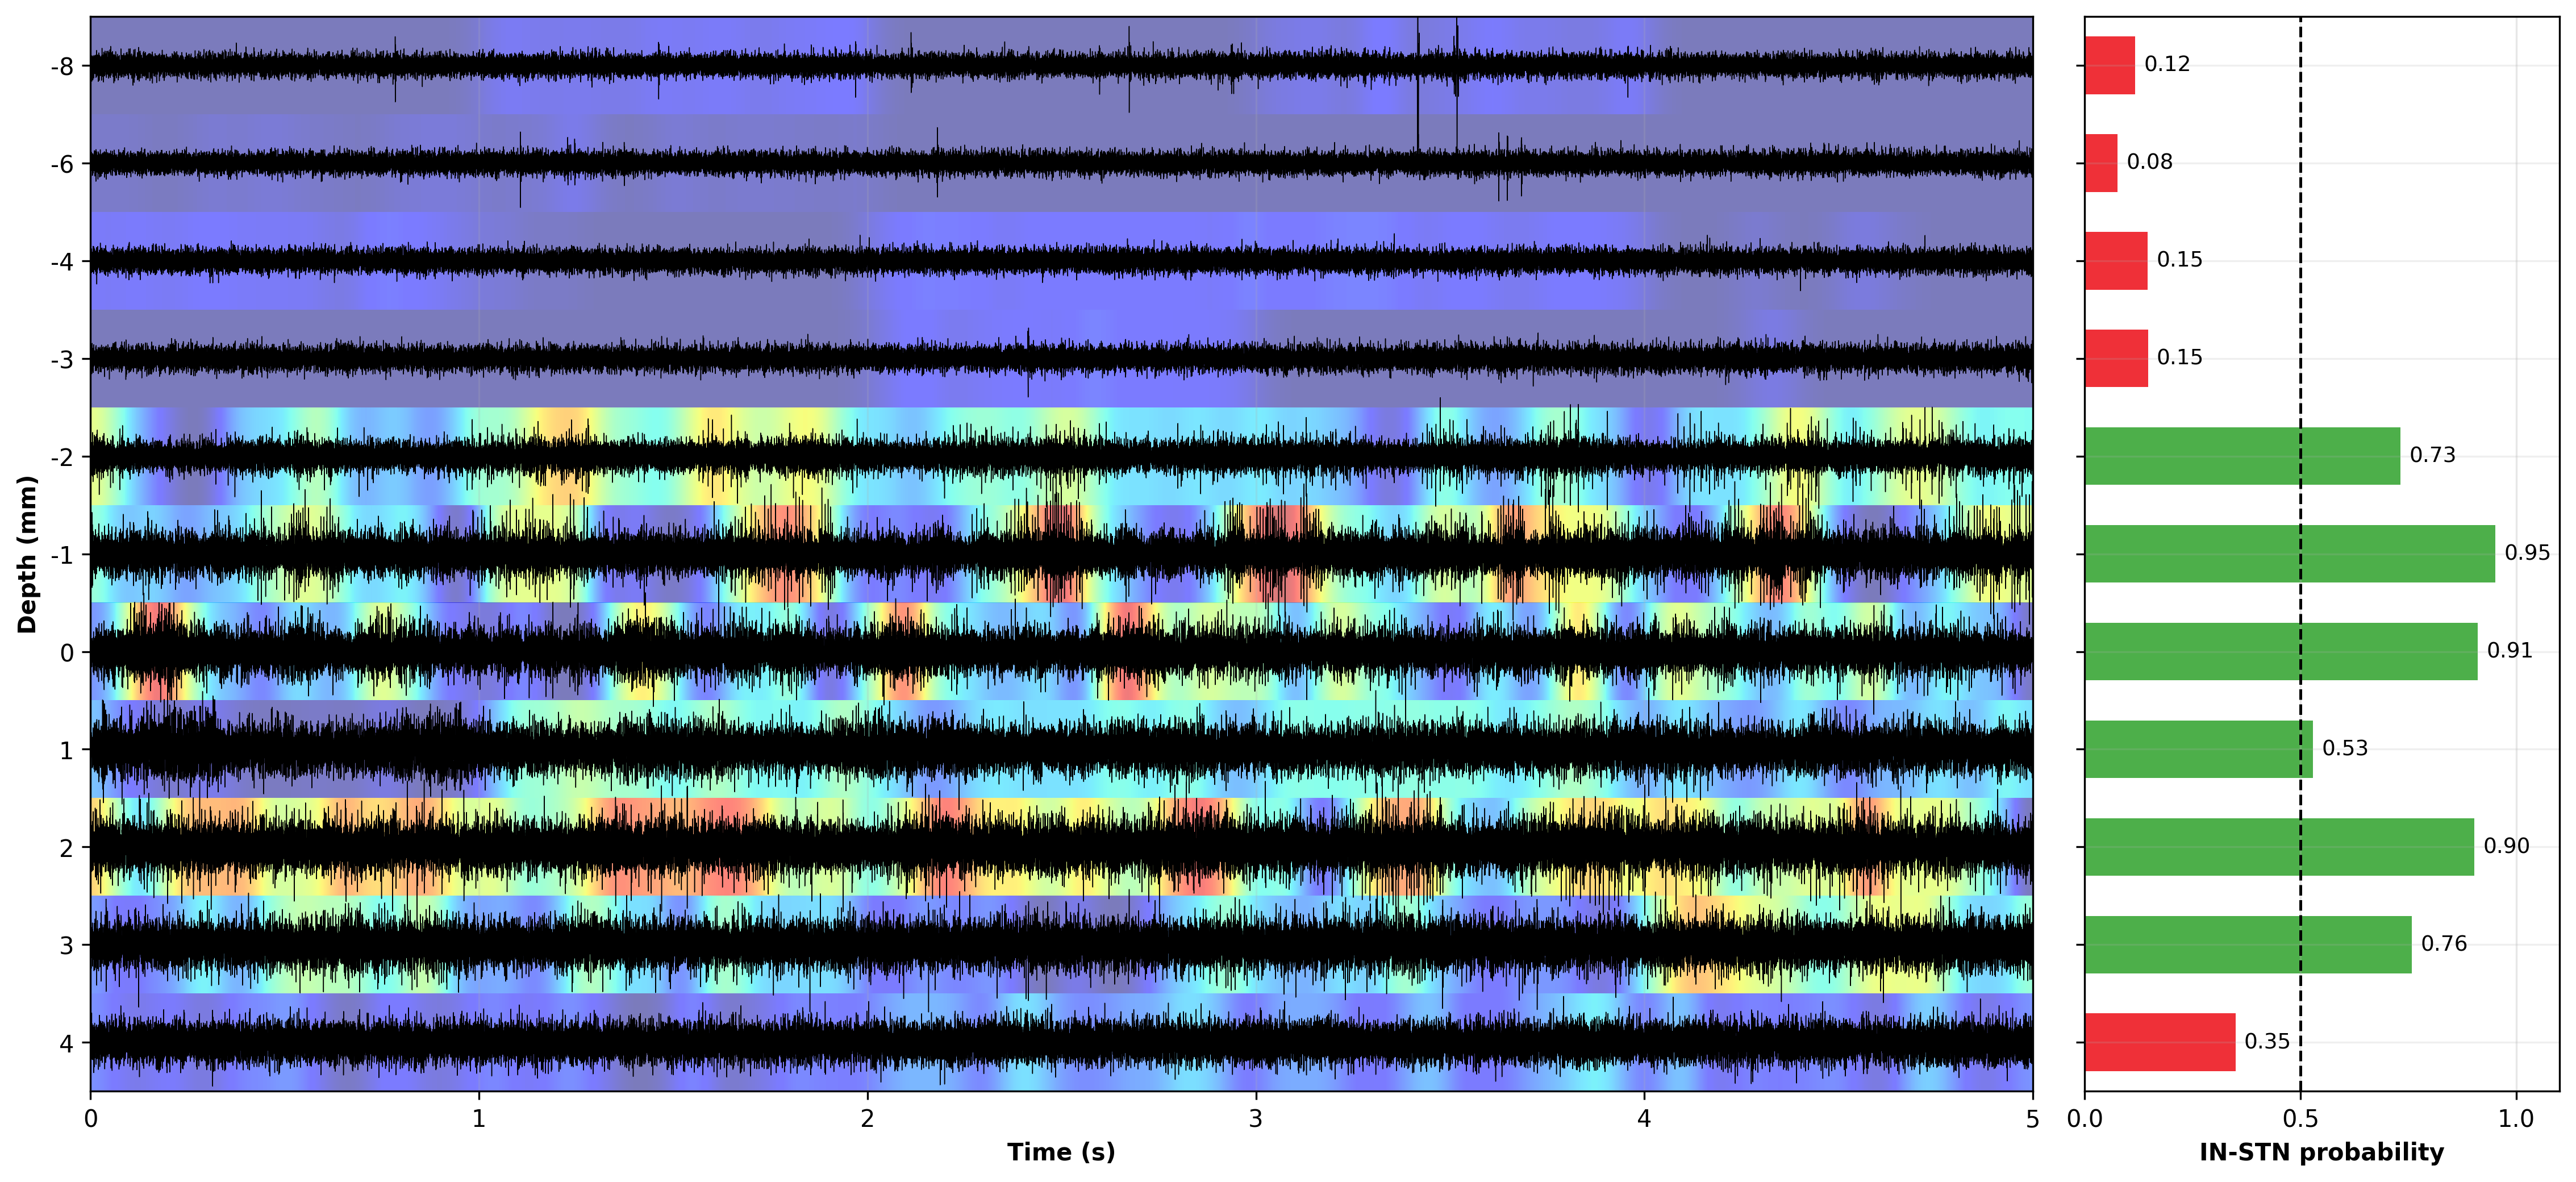

Grad-CAM shape: (11, 50000)
All figures saved to: C:\Users\fabri\Documents\GitHub\XAI-STIM\build_v1\results\main_figures


In [70]:
relevance_maps, trace_probabilities = gradcam1D(
    resampled,
    TARGET_FS,
    model_path=MODELS / 'all_in_one.pt',
    target_class=1,
    return_probabilities=True,
)
gradcam_figure = plot_gradcam(
    resampled,
    relevance_maps,
    trace_probabilities,
    sampling_frequency=TARGET_FS,
    metadata=metadata,
    output_path=FIGURES / '06_gradcam.png',
)
plt.show()
print(f'Grad-CAM shape: {relevance_maps.shape}')
print(f'All figures saved to: {FIGURES}')

## Outputs

After a complete run, `results/main_figures/` contains seven numbered figures documenting import, resampling, windowing, normalization, filtering, inference, and Grad-CAM. The in-memory `prediction_table` contains window metadata, class probabilities, and predicted labels.